[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adkipnis/metabeta/blob/main/demos/04-many-datasets.ipynb)

# many datasets

`sample` takes a list or a dict of DataFrames and fits them all in one call.<br>
This notebook uses it for a simulation-based power analysis: how many schools does a trial need?

In [ ]:
%pip install -q metabeta==0.6.0

## Load a checkpoint

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import norm

from metabeta import Api

device = 'cuda' if torch.cuda.is_available() else 'cpu'
mb = Api.from_pretrained('gaussian', device=device)  # the test score is continuous

Resolving metabeta 'normal' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-normal.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


## Simulate the trials

A cluster-randomized trial assigns whole schools to a new teaching program:

- **Schools**: half get the program, the other half are controls.
- **Students**: 20 per school take a test, scored in standard deviations (SDs).
- **Effect**: the program raises the score by 0.5 SD.
- **Intraclass correlation (ICC)**: 0.2, so a fifth of the score's variance lies between schools.

We simulate 100 trials each with 10, 20 and 40 schools.<br>
The keys `(n_schools, replicate)` index the 300 datasets.

In [2]:
effect, icc, n_students = 0.5, 0.2, 20
rng = np.random.default_rng(0)


def simulate(n_schools):
    """One trial in which half of the schools get the program."""
    school = np.repeat(np.arange(n_schools), n_students)          # (n,) each student's school
    program = rng.permutation(np.repeat([0, 1], n_schools // 2))  # (m,) 1 for program schools
    u = rng.normal(0, np.sqrt(icc), size=n_schools)               # (m,) school deviations
    eps = rng.normal(0, np.sqrt(1 - icc), size=school.size)       # (n,) student deviations
    score = effect * program[school] + u[school] + eps
    return pd.DataFrame(
        {'score': score, 'program': program[school], 'school': [f's{g:02d}' for g in school]}
    )


datasets = {(m, rep): simulate(m) for m in (10, 20, 40) for rep in range(100)}
datasets[(10, 0)].head()

,score,program,school
0,0.096367,0,s00
1,0.300259,0,s00
2,0.951340,0,s00
3,1.515619,0,s00
4,0.468202,0,s00


## Fit all trials in one call

A dict of DataFrames returns a dict of results with the same keys.<br>
`sample` runs the datasets in chunks (`batch_size` in `from_pretrained`) and shows a progress bar
meanwhile.

- **`random_walk=True`**: repairs a low effective sample size (ESS) where it occurs (see
  `02-families`).
- **`seed`**: reproduces the whole call.

In [3]:
%%time
results = mb.sample(
    datasets, formula='score ~ program + (1 | school)',
    random_walk=True,  # where the ESS is low
    seed=0,  # for reproducibility
)

CPU times: user 26.6 s, sys: 530 ms, total: 27.2 s
Wall time: 13.5 s


## Power

A trial detects the effect when its 95% credible interval for `program` excludes 0.<br>
Power is the share of trials that do, per number of schools.<br>
With $R$ trials, its Monte Carlo standard error (MC SE) is $\sqrt{p(1 - p) / R}$.

In [4]:
def detects(result):
    """Whether the 95% interval for `program` excludes 0."""
    lo, hi = mb.posteriorDraws(result)['program'].quantile([0.025, 0.975])  # in the data's units
    return lo > 0 or hi < 0


# a skipped dataset's result is None, so it doesn't count as a trial
detected = pd.Series({key: detects(r) for key, r in results.items() if r is not None})
power = detected.groupby(level=0).agg(trials='size', power='mean').rename_axis('n_schools')
power['MC SE'] = np.sqrt(power['power'] * (1 - power['power']) / power['trials'])
power.round(3)

,trials,power,MC SE
n_schools,,,
10,100,0.32,0.047
20,100,0.50,0.050
40,100,0.78,0.041


### Compared with the design-effect formula

The formula approximates the trial's power with a normal test:

- **Design effect**: $1 + (n - 1)\,\mathrm{ICC}$ for $n$ students per school. Clustering
  inflates the variance of a mean by this factor.
- **Standard error (SE)**: $\sqrt{4 \cdot \text{design effect} / (m n)}$ SD for the
  difference between program and control means over $m$ schools.
- **Power**: $\Phi(0.5 / \mathrm{SE} - 1.96)$.

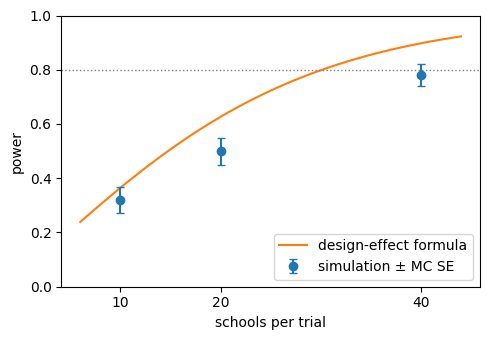

In [5]:
def formula_power(n_schools):
    design_effect = 1 + (n_students - 1) * icc
    se = np.sqrt(4 * design_effect / (n_schools * n_students))  # program − control means
    return norm.cdf(effect / se - norm.ppf(0.975))


grid = np.linspace(6, 44, 100)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(grid, formula_power(grid), color='C1', label='design-effect formula')
ax.errorbar(
    power.index, power['power'], yerr=power['MC SE'], fmt='o', color='C0', capsize=3,
    label='simulation ± MC SE',
)
ax.axhline(0.8, color='gray', ls=':', lw=1)
ax.set(xlabel='schools per trial', ylabel='power', xticks=power.index, ylim=(0, 1))
ax.legend(loc='lower right')
fig.tight_layout()

- **80% power** (the usual target): about 40 schools.
- **The formula**: assumes a normal test with known variances. The simulation checks the
  analysis you will run instead: this model, these priors, these intervals.

## Warnings

Two kinds of warning can appear on a call like this:

- **Skipped datasets**: `sample` skips a dataset it cannot prepare (e.g. fewer schools than the
  checkpoint supports). Its result is `None`, one warning lists the skipped datasets with their
  reasons, and the power table counts fewer trials.
- **Safeguards**: low acceptance, low ESS or a large MAP z (see `01-quickstart`). Each warns once
  per call and names the trials by key, the first ten and then the count. A flagged trial's
  interval can be too narrow, which inflates the power.

Every result keeps its flags in `result.safeguards`.